# Семинар: токенизация и эмбеддинги

Сегодня руками проверим всё, о чём говорили на лекции, и почти всё увидим на картинках.

| Часть | Что делаем | Время |
|---|---|---|
| 0 | Разминка: игра Contexto | 10 мин |
| 1 | BPE своими руками и настоящие токенизаторы | 25 мин |
| 2 | Векторы слов из подсчётов в «маленьком мире» | 15 мин |
| 3 | Настоящие векторы для русского (Navec) | 10 мин |
| 4 | Порядок слов: где ломается мешок слов | 20 мин |

**Как работать.** Запускайте ячейки сверху вниз. Ячейки с пометкой **[нужен интернет]** скачивают библиотеки или модели — в Colab они работают сразу. Всё остальное работает и без интернета.

Блоки **Задание** — для вас: меняйте код, запускайте снова, смотрите, что изменилось.

In [1]:
# Служебные функции для рисунков. Читать не обязательно — просто запустите ячейку.
import re
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.manifold import TSNE

INK, MUTED, PAPER, GRID, ACCENT = "#1B2430", "#646B78", "#F7F5F0", "#DDD6C8", "#B34A1C"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e87ba4", "#008300", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 14, "font.size": 12, "figure.dpi": 110,
})


def draw_tokens(rows, title=None, color_of=None, fontsize=14):
    """Рисует токены цветными плашками. rows — список пар (подпись, список токенов).
    Токен " " означает пробел между словами. color_of(token) может задать цвет токена."""
    fig, ax = plt.subplots(figsize=(13, 0.7 * len(rows) + 0.6))
    for attempt in range(4):                       # если строка не влезла, уменьшаем шрифт и рисуем заново
        ax.cla()
        ax.set_xlim(0, 100)
        ax.set_ylim(-3 * len(rows), 0)
        ax.axis("off")
        renderer, to_data = fig.canvas.get_renderer(), ax.transData.inverted()
        right = 0
        for r, (label, tokens) in enumerate(rows):
            y, x, k = -3 * r - 1.5, 21, 0
            ax.text(0, y, label, va="center", fontsize=11, color=MUTED)
            for t in tokens:
                if t == " ":
                    x += 1.5
                    continue
                text = ax.text(x + 0.4, y, t, va="center", fontsize=fontsize, family="monospace", zorder=3)
                box = text.get_window_extent(renderer)
                (x0, _), (x1, _) = to_data.transform([[box.x0, box.y0], [box.x1, box.y1]])
                w = x1 - x0 + 0.8
                color = color_of(t) if color_of else COLORS[k % 5]
                k += 1
                ax.add_patch(FancyBboxPatch((x, y - 1.1), w, 2.2, boxstyle="round,pad=0,rounding_size=0.4",
                                            zorder=2, facecolor=(color + "30") if color else "#E8E2D6",
                                            edgecolor=color or "#C9C0AE", linewidth=1.3))
                x += w + 0.25
            right = max(right, x)
        if right <= 100:
            break
        fontsize *= 0.95 * (100 - 21) / (right - 21)
    if title:
        ax.set_title(title)
    plt.show()


def heatmap(ax, M, rows, cols, title, fmt="{:.0f}"):
    ax.imshow(M, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(rows)), rows)
    for i in range(len(rows)):
        for j in range(len(cols)):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > 0.6 * M.max() else INK)
    ax.set_title(title)
    ax.grid(False)


def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


def nearest(query, vectors, n=5, exclude=()):
    """Ближайшие слова по косинусу. query — слово или вектор, vectors — словарь {слово: вектор}."""
    if isinstance(query, str):
        exclude = set(exclude) | {query}
        query = vectors[query]
    sims = [(w, cosine(query, v)) for w, v in vectors.items() if w not in exclude]
    return sorted(sims, key=lambda p: -p[1])[:n]


def neighbors_table(words, vectors, n=5):
    rows = {w: ", ".join(f"{u} ({s:.2f})" for u, s in nearest(w, vectors, n)) for w in words if w in vectors}
    return pd.DataFrame.from_dict(rows, orient="index", columns=["ближайшие слова (косинус)"])


def analogy(a, b, c, vectors, exclude=True, n=3):
    """a − b + c: например, «москва − россия + франция»."""
    missing = [w for w in (a, b, c) if w not in vectors]
    if missing:
        return f"нет в словаре: {missing}"
    v = vectors[a] - vectors[b] + vectors[c]
    return nearest(v, vectors, n, exclude={a, b, c} if exclude else ())


def word_map(vectors, groups, title, highlight=()):
    """Карта слов на плоскости (t-SNE). groups — {название группы: [слова]}."""
    words = [w for ws in groups.values() for w in ws if w in vectors] + [w for w in highlight if w in vectors]
    X = np.array([vectors[w] for w in words])
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    xy = TSNE(n_components=2, perplexity=min(10, len(words) - 1), init="pca", metric="cosine",
              random_state=0).fit_transform(X)
    pos = dict(zip(words, xy))
    fig, ax = plt.subplots(figsize=(12, 7))
    for (name, ws), color in zip(groups.items(), COLORS):
        ws = [w for w in ws if w in pos]
        pts = np.array([pos[w] for w in ws])
        ax.scatter(pts[:, 0], pts[:, 1], s=80, color=color, edgecolor=PAPER, linewidth=1.5, label=name, zorder=3)
        for w in ws:
            ax.annotate(w, pos[w], xytext=(5, 4), textcoords="offset points", fontsize=11)
    for w in highlight:
        if w in pos:
            ax.scatter(*pos[w], s=220, facecolor="none", edgecolor=ACCENT, linewidth=2.5, zorder=4)
            ax.scatter(*pos[w], s=80, color=ACCENT, zorder=5)
            ax.annotate(w, pos[w], xytext=(8, -14), textcoords="offset points", fontsize=13,
                        color=ACCENT, fontweight="bold")
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    ax.set_title(title)
    ax.axis("off")
    plt.show()


print("Готово: можно идти дальше")

Готово: можно идти дальше


## 1. Токенизация своими руками

### 1.1 BPE за 30 строк

Алгоритм с лекции: разбиваем слова на буквы, находим самую частую пару соседей, склеиваем её в новый токен, повторяем. Результат обучения — упорядоченный список слияний.

In [2]:
def merge(word, pair):
    """Склеивает в слове (кортеже токенов) все вхождения пары."""
    out, i = [], 0
    while i < len(word):
        if word[i:i + 2] == pair:
            out.append(pair[0] + pair[1])
            i += 2
        else:
            out.append(word[i])
            i += 1
    return tuple(out)


def train_bpe(freqs, n_merges):
    """freqs — {слово: частота}. Возвращает список слияний и состояние корпуса после каждого шага."""
    vocab = {tuple(w): f for w, f in freqs.items()}
    merges, history = [], [("буквы", dict(vocab))]
    for _ in range(n_merges):
        pairs = Counter()
        for word, f in vocab.items():
            for p in zip(word, word[1:]):
                pairs[p] += f
        if not pairs:
            break
        best = max(pairs, key=pairs.get)
        merges.append(best)
        vocab = {merge(w, best): f for w, f in vocab.items()}
        history.append((f"{best[0]} + {best[1]} ({pairs[best]})", dict(vocab)))
    return merges, history


def encode(word, merges):
    """Режет новое слово выученными слияниями — строго в порядке обучения."""
    tokens = tuple(word)
    for pair in merges:
        tokens = merge(tokens, pair)
    return list(tokens)

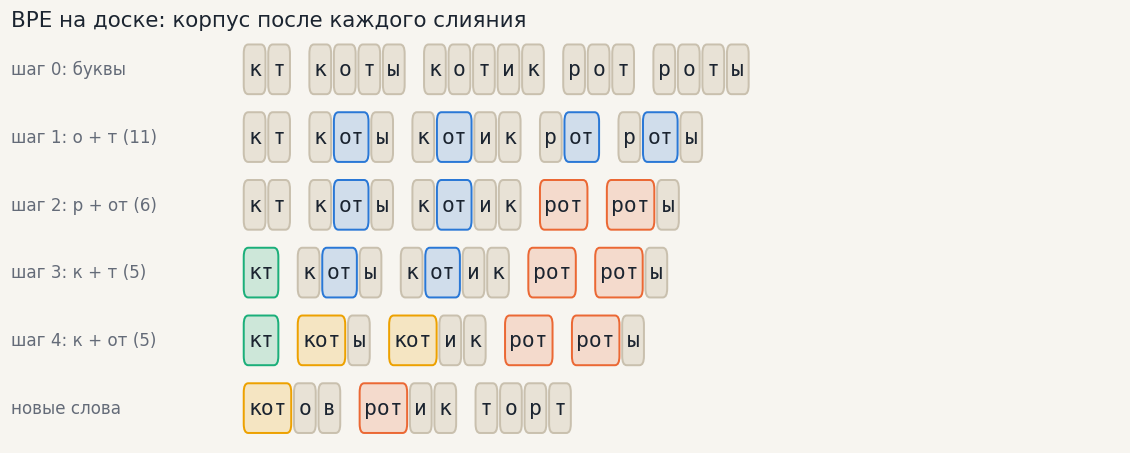

In [4]:
board = {"кт": 5, "коты": 3, "котик": 2, "рот": 4, "роты": 2}
merges, history = train_bpe(board, 4)

new_tokens = ["".join(p) for p in merges]
color_of = lambda t: COLORS[new_tokens.index(t)] if t in new_tokens else None   # буквы — серые

rows = []
for step, (label, vocab) in enumerate(history):
    tokens = []
    for word in vocab:
        tokens += list(word) + [" "]
    rows.append((f"шаг {step}: {label}", tokens))
rows.append(("новые слова", sum([encode(w, merges) + [" "] for w in ["котов", "ротик", "торт"]], [])))
draw_tokens(rows, "BPE на доске: корпус после каждого слияния", color_of=color_of)

**Задание.** Добавьте в корпус `board` слово «торт» с частотой 3 и запустите ячейку снова. Как изменились слияния? Почему?

### 1.2 BPE на настоящем тексте

Возьмём небольшую сказку про кота, который придумал токенизацию, и обучим на ней BPE.

In [5]:
TEXT = """
Кот Тимофей жил в старом доме у реки. Каждое утро кот выходил во двор и долго смотрел на воду.
Соседские коты завидовали Тимофею: у него был тёплый подоконник, миска с молоком и хозяйка,
которая читала ему вслух. Хозяйка читала много: книги о далёких странах, книги о звёздах,
книги о котах и собаках. Кот слушал внимательно и иногда засыпал, не дослушав главу до конца.
Однажды хозяйка принесла домой новую книгу. Книга была толстая, с картинками и длинными словами.
«Токенизация», — прочитала хозяйка и рассмеялась. Кот не знал, что значит это слово, но слово ему
понравилось. Он попробовал разделить его на кусочки: «то», «кен», «изация». Кусочки получились
странные, но знакомые. Ведь кот уже слышал слова «организация» и «цивилизация», а значит, мог
догадаться, что новое слово тоже обозначает какой-то процесс.
С тех пор кот Тимофей стал разбирать на кусочки все незнакомые слова. Длинные слова он делил
на короткие части, короткие слова запоминал целиком. Частые кусочки он узнавал сразу, редкие
кусочки разглядывал подольше. Соседские коты смеялись над ним, но Тимофей не обижался.
Он понимал: чтобы читать быстро, не нужно знать все слова на свете. Достаточно знать хорошие
кусочки слов и уметь их складывать.
Вечером хозяйка снова читала вслух. Кот слушал, узнавал знакомые кусочки и радовался. Слова больше
не казались ему страшными. Даже самые длинные слова, вроде «достопримечательность» или
«электрификация», складывались из знакомых частей, как дом складывается из кирпичей. А если кусочек
попадался совсем незнакомый, кот просто запоминал его буквы и шёл дальше.
Так кот Тимофей, сам того не зная, придумал алгоритм, который сегодня работает внутри больших
языковых моделей. Модели тоже читают тексты кусочками, тоже узнают частые части слов и тоже
собирают из них новые слова. Только читают они не одну книгу, а миллионы книг, и кусочков у них
не сто, а десятки тысяч.
"""

words = re.findall(r"\w+", TEXT.lower())
freqs = Counter(words)
print(f"Слов в тексте: {len(words)}, разных слов: {len(freqs)}")
print("Самые частые:", freqs.most_common(8))

Слов в тексте: 289, разных слов: 191
Самые частые: [('и', 12), ('кот', 9), ('не', 8), ('слова', 8), ('кусочки', 7), ('на', 5), ('хозяйка', 5), ('тимофей', 4)]


In [6]:
merges, _ = train_bpe(freqs, 300)
print("Первые 30 выученных токенов:")
print(", ".join("".join(p) for p in merges[:30]))

Первые 30 выученных токенов:
ко, ал, на, ов, сл, то, ки, ни, ст, ка, со, ра, слов, зна, кот, ро, до, не, ли, мо, по, чи, ку, кусо, кусоч, ые, ми, чит, но, слова


**Вопрос.** Какие токены появились первыми — корни, окончания или служебные слова? Почему именно они?

Теперь посмотрим, как длина токенов зависит от числа слияний. Метрика **fertility** — сколько токенов в среднем приходится на одно слово.

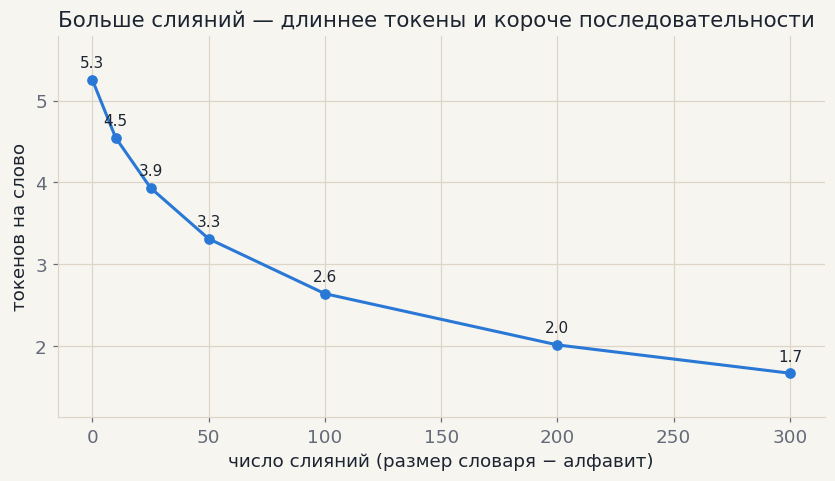

In [7]:
steps = [0, 10, 25, 50, 100, 200, 300]
fertility = [np.mean([len(encode(w, merges[:n])) for w in words]) for n in steps]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(steps, fertility, marker="o", color=COLORS[0], linewidth=2)
for n, f in zip(steps, fertility):
    ax.annotate(f"{f:.1f}", (n, f), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=10)
ax.set_xlabel("число слияний (размер словаря − алфавит)")
ax.set_ylabel("токенов на слово")
ax.set_title("Больше слияний — длиннее токены и короче последовательности")
ax.margins(y=0.15)
ax.grid(color=GRID)
plt.show()

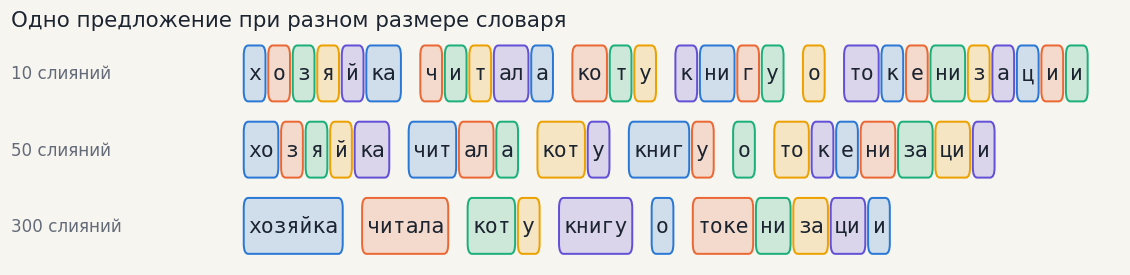

In [8]:
sentence = "Хозяйка читала коту книгу о токенизации"
rows = []
for n in [10, 50, 300]:
    tokens = []
    for w in sentence.lower().split():
        tokens += encode(w, merges[:n]) + [" "]
    rows.append((f"{n} слияний", tokens))
draw_tokens(rows, "Одно предложение при разном размере словаря")

**Задание.** Придумайте предложение, в котором много слов, которых нет в сказке. Как оно режется? Какое слово распалось на больше всего кусков?

### 1.3 Настоящие токенизаторы [нужен интернет]

Библиотека `tiktoken` содержит токенизаторы моделей OpenAI. Сравним старый (GPT-2) и новый (GPT-4o) на одной фразе по-русски и по-английски.

In [9]:
!pip install -q tiktoken

In [ ]:
import tiktoken

phrases = {
    "EN": "The cat is sleeping on the warm windowsill",
    "RU": "Кошка спит на тёплом подоконнике",
}
encoders = {name: tiktoken.get_encoding(name) for name in ["gpt2", "cl100k_base", "o200k_base"]}

counts = pd.DataFrame({name: {lang: len(enc.encode(p)) for lang, p in phrases.items()}
                       for name, enc in encoders.items()}).T
counts["RU / EN"] = (counts["RU"] / counts["EN"]).round(1)
counts

In [ ]:
def pieces(enc, text):
    """Токены как строки. Кусок кириллической буквы (половина байтов) покажется как «�»."""
    return [enc.decode_single_token_bytes(t).decode("utf-8", errors="replace").replace(" ", "▁")
            for t in enc.encode(text)]

draw_tokens([(f"{name}: {lang}", pieces(enc, text))
             for name, enc in [("gpt2", encoders["gpt2"]), ("o200k", encoders["o200k_base"])]
             for lang, text in phrases.items()],
            "Одна фраза — разное число токенов", fontsize=12)

**Задание.** Найдите фразу, у которой «налог на русский» (отношение RU / EN) максимальный. Попробуйте длинные слова, имена, числа, эмодзи. Почему у GPT-2 появляются кусочки «�»?

## 2. Векторы слов из подсчётов: «маленький мир»

Сгенерируем корпус из простых предложений, в которых мы сами знаем все правила: животные спят и мяукают, еду режут и покупают, рыцари носят оружие. Слово «лук» специально живёт в двух мирах: его режут для супа и из него стреляют.

Предложения уже лемматизированы — как в корпусах, на которых обучены модели RusVectōrēs.

In [ ]:
random.seed(0)
CAPITALS = {"москва": "россия", "париж": "франция", "берлин": "германия", "рим": "италия"}
LANGS = {"россия": "русский", "франция": "французский", "германия": "немецкий", "италия": "итальянский"}
SLOTS = {
    "животное": ["кот", "кошка", "собака", "пёс", "хомяк", "попугай"],
    "кошачьи": ["кот", "кошка"], "собачьи": ["собака", "пёс"],
    "еда": ["суп", "хлеб", "сыр", "картошка", "морковь", "лук"], "овощ": ["картошка", "морковь", "лук"],
    "напиток": ["чай", "кофе", "молоко", "сок"],
    "температура": ["горячий", "холодный", "тёплый", "ледяной"],
    "оружие": ["меч", "копьё", "щит", "арбалет", "лук"], "стрелковое": ["лук", "арбалет"],
}
TEMPLATES = [
    "{животное} спать на диван", "погладить {животное}", "{животное} играть с мячик",
    "кормить {животное} утром", "{кошачьи} мяукать", "{собачьи} лаять", "попугай летать по комната",
    "хомяк грызть морковь", "купить {еда} в магазин", "резать {овощ} нож", "{еда} очень вкусный",
    "есть {еда} на обед", "суп с {овощ}", "пить {напиток}", "чашка {напиток}", "{температура} {напиток}",
    "налить {напиток} в кружка", "{температура} суп", "на улица очень {температура}", "{температура} вода",
    "рыцарь носить {оружие}", "воин взять {оружие}", "стрелять из {стрелковое}", "{оружие} висеть на стена",
    "GEO", "GEO",
]
GEO = ["{c} столица {k}", "жить в {c}", "поехать в {k}", "в {k} говорить на {l}",
       "в {c} говорить на {l}", "{c} большой город", "{k} красивый страна"]


def make_sentence():
    template = random.choice(TEMPLATES)
    if template == "GEO":
        c = random.choice(list(CAPITALS))
        return random.choice(GEO).format(c=c, k=CAPITALS[c], l=LANGS[CAPITALS[c]]).split()
    return [random.choice(SLOTS[t[1:-1]]) if t.startswith("{") else t for t in template.split()]


corpus = [make_sentence() for _ in range(6000)]
for s in corpus[:8]:
    print(" ".join(s))

### 2.1 Матрица совстречаемости и PPMI

Считаем, сколько раз каждое слово встретилось в одном предложении с каждым другим. Строка матрицы — это и есть вектор слова.

In [ ]:
vocab = sorted({w for s in corpus for w in s})
idx = {w: i for i, w in enumerate(vocab)}
N = np.zeros((len(vocab), len(vocab)))
for s in corpus:
    for a in s:
        for b in s:
            if a != b:
                N[idx[a], idx[b]] += 1


def ppmi(N, alpha=0.75):
    p_w = N.sum(1, keepdims=True) / N.sum()
    p_c = N.sum(0) ** alpha
    p_c = p_c / p_c.sum()
    with np.errstate(divide="ignore"):
        return np.maximum(np.log(N / N.sum() / (p_w * p_c)), 0)


M = ppmi(N)
rows = ["кот", "собака", "чай", "кофе", "лук", "москва"]
cols = ["в", "на", "очень", "мяукать", "лаять", "пить", "резать", "стрелять", "столица"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
heatmap(axes[0], N[np.ix_([idx[w] for w in rows], [idx[c] for c in cols])], rows, cols, "Сырые счётчики")
heatmap(axes[1], M[np.ix_([idx[w] for w in rows], [idx[c] for c in cols])], rows, cols, "PPMI", fmt="{:.1f}")
plt.tight_layout()
plt.show()

**Вопрос.** Что случилось со столбцами «в» и «на» после PPMI? А со столбцом «мяукать»? Почему у «лука» два ярких столбца?

### 2.2 SVD и карта смыслов

Сжимаем матрицу PPMI до 20 чисел на слово с помощью SVD и рисуем слова на плоскости.

In [ ]:
U, S, _ = np.linalg.svd(M)
k = 20
E = U[:, :k] * np.sqrt(S[:k])
vectors = {w: E[idx[w]] for w in vocab}

groups = {
    "животные": SLOTS["животное"], "еда": ["суп", "хлеб", "сыр", "картошка", "морковь"],
    "напитки": SLOTS["напиток"], "температура": SLOTS["температура"],
    "оружие": ["меч", "копьё", "щит", "арбалет"], "столицы": list(CAPITALS), "страны": list(LANGS),
}
word_map(vectors, groups, "Маленький мир: векторы из подсчётов (PPMI + SVD, k = 20)", highlight=["лук"])

In [ ]:
neighbors_table(["кот", "лук", "горячий", "чай", "меч", "москва"], vectors)

**Вопросы.** Где оказался «лук» и кто его соседи? Почему «горячий» ближе всего к «холодному»? Вспомните разминку.

### 2.3 Аналогии

Проверим знаменитую арифметику: «москва − россия + франция ≈ ?». Сравним честный поиск (с исключением слов запроса) и поиск без исключения.

In [ ]:
print("с исключением слов запроса:", analogy("москва", "россия", "франция", vectors))
print("без исключения:            ", analogy("москва", "россия", "франция", vectors, exclude=False))

**Задание.**

1. Поменяйте `k = 20` на `k = 5` и запустите ячейки 2.2–2.3 снова. Что стало с аналогией и с картой? Почему?
2. Сделайте ещё одно многозначное слово. Например, добавьте в `TEMPLATES` шаблоны `"открыть дверь {ключ}"` и `"пить вода из {ключ}"` и слот `"ключ": ["ключ"]` (или придумайте своё). Где окажется новое слово на карте?

## 3. Настоящие векторы для русского [нужен интернет]

Navec — компактные (около 50 МБ) векторы для русского от проекта Natasha, обученные на художественной литературе. Используем те же функции, что и для «маленького мира».

In [ ]:
!pip install -q navec
!wget -q -nc https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

In [ ]:
from navec import Navec

navec = Navec.load("navec_hudlit_v1_12B_500K_300d_100q.tar")

real_groups = {
    "животные": ["кот", "кошка", "собака", "пёс", "хомяк", "попугай", "лошадь", "корова"],
    "еда": ["суп", "хлеб", "сыр", "картошка", "морковь", "капуста", "чеснок"],
    "оружие": ["меч", "копьё", "щит", "арбалет", "стрела", "сабля"],
    "температура": ["горячий", "холодный", "тёплый", "ледяной", "раскалённый", "прохладный"],
    "люди": ["король", "королева", "мужчина", "женщина", "принц", "принцесса", "царь", "царица"],
    "города": ["москва", "париж", "берлин", "рим", "лондон", "мадрид"],
    "страны": ["россия", "франция", "германия", "италия", "англия", "испания"],
}
words = [w for ws in real_groups.values() for w in ws] + ["лук", "замок", "ключ", "коса"]
real = {w: navec[w] for w in words if w in navec}
print(f"Нашлось {len(real)} слов из {len(words)}")

In [ ]:
word_map(real, real_groups, "Navec: настоящие векторы для русского", highlight=["лук", "замок"])

In [ ]:
print("король − мужчина + женщина")
print("  с исключением: ", analogy("король", "мужчина", "женщина", real))
print("  без исключения:", analogy("король", "мужчина", "женщина", real, exclude=False))
print("москва − россия + франция")
print("  с исключением: ", analogy("москва", "россия", "франция", real))

In [ ]:
pairs = [("горячий", "раскалённый", "синонимы"), ("горячий", "холодный", "антонимы"),
         ("тёплый", "прохладный", "антонимы"), ("ледяной", "холодный", "синонимы"),
         ("король", "царь", "синонимы"), ("король", "королева", "пара")]
labels = [f"{a} — {b}" for a, b, _ in pairs]
sims = [cosine(real[a], real[b]) for a, b, _ in pairs]
kind_color = {"синонимы": COLORS[0], "антонимы": COLORS[1], "пара": COLORS[2]}
colors = [kind_color[kind] for _, _, kind in pairs]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(labels[::-1], sims[::-1], color=colors[::-1], height=0.6)
for i, s in enumerate(sims[::-1]):
    ax.text(s + 0.01, i, f"{s:.2f}", va="center")
ax.set_xlabel("косинусная близость")
ax.set_title("Кто ближе: синонимы (синие), антонимы (оранжевые) или пара «король — королева» (зелёная)?")
plt.show()

In [ ]:
neighbors_table(["лук", "замок", "ключ", "коса"], real)

**Задание.**

1. Что вернула аналогия «король − мужчина + женщина» без исключения слов запроса? Как это связано с лекцией?
2. Какие значения многозначных слов («замок», «коса», «ключ») видны среди соседей, а какие потерялись? Важно: соседи ищутся только среди слов нашего небольшого списка — добавьте в `real_groups` слова, которые помогут увидеть второе значение.
3. Добавьте в `pairs` свои пары синонимов и антонимов. Подтверждается ли картина?

## 4. Порядок слов: где ломается мешок слов

Сгенерируем отзывы трёх видов:

- **простые**: «фильм отличный», «сериал очень скучный»;
- **локальное отрицание**: «фильм не плохой а отличный» — смысл зависит от соседних слов;
- **дальнее отрицание**: «не могу сказать что этот длинный мрачный фильм мне понравился» — «не» и глагол разделяют много слов.

Обучим логистическую регрессию на трёх наборах признаков: только отдельные слова (мешок слов), слова и пары соседей (окно 2), слова, пары и тройки (окно 3). Окно ширины k — это то же, что фильтр ширины k в TextCNN.

In [ ]:
random.seed(1)
POS = ["отличный", "прекрасный", "хороший", "замечательный"]
NEG = ["плохой", "ужасный", "скучный", "слабый"]
NOUNS = ["фильм", "сериал", "спектакль", "мультфильм"]
FILLERS = ["длинный", "затянутый", "мрачный", "медленный", "громкий", "новый", "странный", "дорогой"]


def review(kind):
    noun, label = random.choice(NOUNS), random.randint(0, 1)          # 1 — положительный
    good, bad = random.choice(POS), random.choice(NEG)
    if kind == "простые":
        return f"{noun} {random.choice(['', 'очень', 'просто'])} {good if label else bad}", label
    if kind == "локальное отрицание":
        return (f"{noun} не {bad} а {good}" if label else f"{noun} не {good} а {bad}"), label
    negated = random.randint(0, 1)                                      # «не могу сказать» переворачивает смысл
    liked = label ^ negated
    start = "не могу сказать" if negated else "могу честно сказать"
    end = "мне понравился" if liked else "меня разочаровал"
    middle = " ".join(random.sample(FILLERS, 4))
    return f"{start} что этот {middle} {noun} {end}", label


KINDS = ["простые", "локальное отрицание", "дальнее отрицание"]
train = [review(kind) for kind in KINDS for _ in range(600)]
test = {kind: [review(kind) for _ in range(300)] for kind in KINDS}
for kind in KINDS:
    text, label = test[kind][0]
    print(f"{kind:>20}: {text}  →  {'+' if label else '−'}")

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

models = {"мешок слов": (1, 1), "окно 2": (1, 2), "окно 3": (1, 3)}
scores = {}
for name, ngrams in models.items():
    vectorizer = CountVectorizer(ngram_range=ngrams, token_pattern=r"(?u)\b\w+\b")
    X = vectorizer.fit_transform([t for t, _ in train])
    clf = LogisticRegression(max_iter=2000).fit(X, [y for _, y in train])
    scores[name] = {kind: clf.score(vectorizer.transform([t for t, _ in data]), [y for _, y in data])
                    for kind, data in test.items()}

scores = pd.DataFrame(scores)
fig, ax = plt.subplots(figsize=(11, 4.8))
width = 0.25
for i, name in enumerate(scores.columns):
    xs = np.arange(len(KINDS)) + (i - 1) * width
    ax.bar(xs, scores[name] * 100, width=width - 0.03, color=COLORS[i], label=name)
    for x, v in zip(xs, scores[name] * 100):
        ax.text(x, v + 1.5, f"{v:.0f}", ha="center", fontsize=10)
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1)
ax.text(-0.45, 52, "угадывание", color=MUTED, fontsize=10)
ax.set_xticks(range(len(KINDS)), KINDS)
ax.set_ylabel("точность на тесте, %")
ax.set_ylim(0, 112)
ax.set_title("Мешок слов не видит порядок, окно видит только соседей")
ax.legend(frameon=False, loc="upper right")
plt.show()
scores.round(2)

**Вопросы.**

1. Почему мешок слов не справляется с локальным отрицанием, хотя видел такие примеры при обучении?
2. Почему окно 2 справляется с локальным отрицанием, но не с дальним?
3. Поможет ли окно 5? А окно 10? Проверьте, поменяв `models`. Что придётся делать, если отрицание может стоять сколь угодно далеко?

**Задание.** Придумайте свой вид отзывов, который сломает окно 3, и добавьте его в `review`.

## Итоги

- BPE строит словарь из частых кусочков: частые слова становятся одним токеном, редкие собираются из частей, а незнакомых токенов не бывает.
- Один и тот же текст стоит разное число токенов на разных языках и в разных токенизаторах.
- Векторы слов можно получить без нейросети: совстречаемость → PPMI → SVD. Похожие слова оказываются рядом, но рядом оказываются и антонимы, а у многозначного слова один вектор на все значения.
- Мешок слов теряет порядок. Окно (n-граммы, свёртки) видит только соседей. Чтобы связать далёкие слова, нужна модель, которая читает текст по порядку и помнит прочитанное. Это рекуррентные сети — тема следующего занятия.